# 3.4 · A multi-factor long-short strategy

> **Needs:** the research cache (notebook 1.1) and the database.
>
> **Produces:** registered runs of the families `multi_factor_ls`, `single_factor_ls` and `revised_ls` (the rebuilt book). It also explains the run registry, the deflated Sharpe ratio and the hold-out that every strategy notebook uses.

**Hypothesis:** stocks with certain characteristics (*factors*) have historically earned higher returns than others,
a cross-sectional pattern documented in the asset-pricing literature (Fama-French, Carhart, Asness et al.). A
**long-short** portfolio buys the stocks that score best and *sells short* those that score worst. If the spread
between them is positive, the portfolio earns it **largely independent of the market's direction**: its return is
close to the factor premium alone.

**Short selling:** borrowing a share, selling it, and buying it back later to return to the lender. The short seller
gains if the price falls and loses if it rises, and pays a borrowing fee meanwhile.

| Factor | Economic intuition | Measurement |
|---|---|---|
| **Value** | cheap stocks earn a premium (risk compensation or investor over-extrapolation) | earnings, sales, book value and operating profit relative to market capitalisation |
| **Quality** | profitable, conservatively financed firms are under-priced | return on equity and on invested capital, gross profit to assets, low leverage |
| **Momentum** | past 12-month winners keep outperforming for some months (under-reaction) | the return over the past 12 months excluding the most recent month (to avoid short-term reversal) |
| **Low volatility** | low-risk stocks earn more risk-adjusted return than the CAPM predicts | low standard deviation of daily returns over the past year |

Each factor is standardised cross-sectionally into a **z-score** per stock and month, $z_i = (x_i - \bar{x}) / s_x$,
and the four z-scores are averaged into one **composite score** (a weighted mean: the weights are a parameter,
`FACTOR_WEIGHTS` in the first code cell, equal by default).

**Portfolio rules** (every setting is recorded in the configuration below):

* **Universe:** the S&P 1500 constituents (S&P 500 + 400 + 600) *as of each date* - never today's list applied to the
  past, which would introduce survivorship bias.
* **Monthly rebalance:** long the top decile by composite score, short the bottom decile. A position already held is
  kept until it leaves the top (bottom) quintile - a *buffer* that reduces turnover from names oscillating around the
  cut-off.
* **Beta-neutral:** each side is scaled so that the portfolio's market beta is zero; high-beta stocks get smaller
  positions, so market moves cancel between the two legs.
* **Transaction costs:** every trade pays 0.10 % for large caps rising to 0.50 % for small caps, and every short pays
  a borrowing fee. All results below are *net* of costs.
* **Point-in-time:** each rebalance uses only prices and statements published before that date.

In [1]:
from dataclasses import replace

import pandas as pd
from IPython.display import display

from equity_research.analytics.indices import vendor_returns
from equity_research.data.cache import ResearchCache
from equity_research.strategies.factor_strategy import StrategyConfig, run_strategy
from research_core import charts
from research_core.analytics.performance.tracking import calendar_years, tracking
from research_core.data.db.engine import get_engine
from research_core.engine.registry import HoldoutClosedError, deflated_sharpe

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")

charts.style()
cache = ResearchCache()
TODAY = pd.Timestamp.today().strftime("%Y-%m-%d")

engine = get_engine()
# The composite score is the weighted mean of these factors' z-scores. Only the ratios matter, and any factor
# run_strategy knows can be added (its error lists them). Equal weights are the notebook's registered trials; any
# change is a new trial, so choose the weights before seeing the results.
FACTOR_WEIGHTS = {"value": 1.0, "quality": 1.0, "momentum": 1.0, "low_vol": 1.0}
config = StrategyConfig(
    family="multi_factor_ls",
    universe="SP1500",
    start="2004-01-01",
    end="2024-12-31",
    factors=tuple(FACTOR_WEIGHTS.items()),
    enter=0.10,
    exit_=0.20,
    long_only=False,
    beta_neutral=True,
)
result = run_strategy(cache, config, engine=engine)
print("Registered as research run", result.run_id)

left out 1078 facts of 2 companies in ['GBP']


Registered as research run 213


## Performance

,value,meaning
cagr,0.04484,average growth per year
vol,0.1639,typical yearly ups and downs
sharpe,0.3502,return per unit of risk
max_drawdown,-0.4965,worst fall from a high
turnover,7.049,times the book is traded per year
beta,-0.03166,NaN
alpha,0.05771,NaN
active_return,-0.05261,NaN
tracking_error,0.2107,NaN
information_ratio,-0.264,NaN


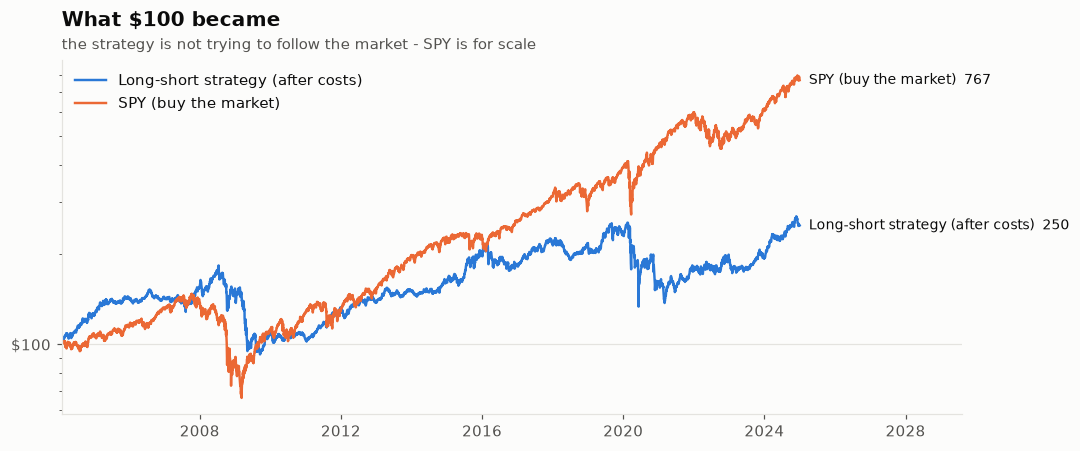

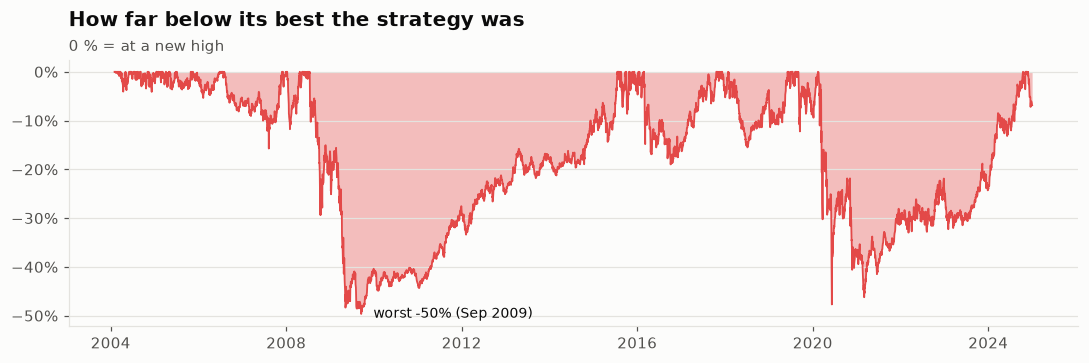

In [2]:
MEANING = {
    "cagr": "average growth per year",
    "vol": "typical yearly ups and downs",
    "sharpe": "return per unit of risk",
    "max_drawdown": "worst fall from a high",
    "turnover": "times the book is traded per year",
    "trials": "versions of this idea tried so far",
    "deflated_sharpe": "chance the result is real, not luck",
}
metrics = pd.DataFrame({"value": result.metrics}).assign(meaning=lambda d: d.index.map(MEANING))
display(metrics)
spy = vendor_returns(cache, "SPY", total=True)
net = result.backtest.net[result.backtest.net.index >= pd.Timestamp(config.start)]
fig = charts.growth(
    {"Long-short strategy (after costs)": net, "SPY (buy the market)": spy},
    "What $100 became",
    subtitle="the strategy is not trying to follow the market - SPY is for scale",
)
fig = charts.drawdown(net, "How far below its best the strategy was", subtitle="0 % = at a new high")

Calendar-year returns. A beta-neutral book should show little correlation with the market: it can gain in a year the
market falls, and lag in a year it rallies.

Market sensitivity (beta to SPY): 0.19  - near 0 is what beta-neutral aims for


,Strategy,SPY
trade_date,,
2004,25.4%,8.6%
2005,13.1%,4.8%
2006,0.8%,15.8%
2007,8.4%,5.1%
2008,-1.1%,-36.8%
2009,-29.6%,26.4%
2010,-3.6%,15.1%
2011,26.8%,1.9%
2012,4.6%,16.0%


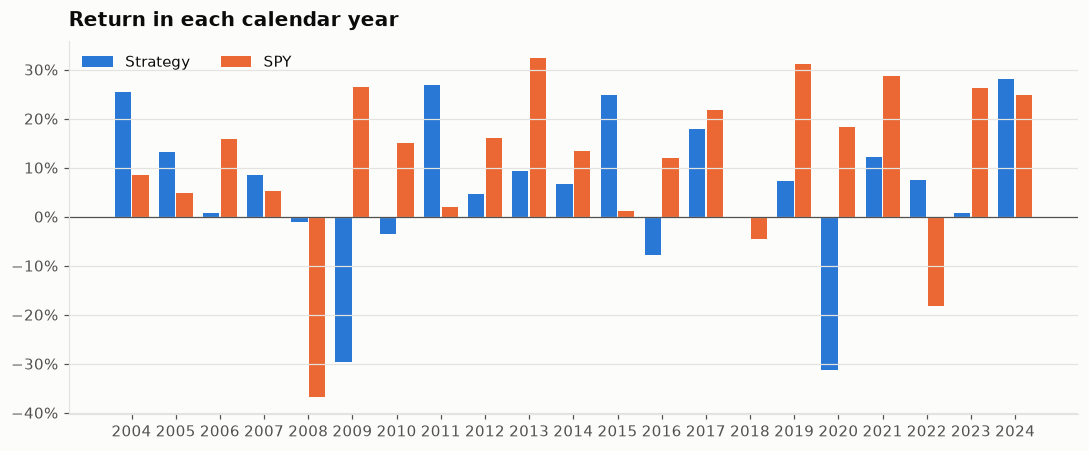

In [3]:
years = calendar_years({"Strategy": net, "SPY": spy})
fig = charts.yearly_bars(years, "Return in each calendar year")
print(f"Market sensitivity (beta to SPY): {tracking(net, spy)['beta']:.2f}  - near 0 is what beta-neutral aims for")
display(years.style.format("{:.1%}"))

## Factor attribution

The same portfolio built on one factor at a time. Each run is a separate *trial* of the hypothesis "single-factor
long-short" and is registered like the first, so the multiple-testing correction below counts it.

In [4]:
singles = {}
for name in FACTOR_WEIGHTS:
    one = run_strategy(cache, replace(config, family="single_factor_ls", factors=((name, 1.0),)), engine=engine)
    singles[name] = one.metrics
singles["all four"] = result.metrics
display(
    pd.DataFrame(singles)
    .T[["cagr", "vol", "sharpe", "max_drawdown", "turnover"]]
    .style.format(
        {"cagr": "{:.1%}", "vol": "{:.1%}", "sharpe": "{:.2f}", "max_drawdown": "{:.0%}", "turnover": "{:.1f}"}
    )
)

left out 1078 facts of 2 companies in ['GBP']


left out 1078 facts of 2 companies in ['GBP']


left out 1078 facts of 2 companies in ['GBP']


left out 1078 facts of 2 companies in ['GBP']


,cagr,vol,sharpe,max_drawdown,turnover
value,-0.7%,13.6%,0.01,-64%,4.6
quality,4.6%,10.8%,0.47,-25%,3.8
momentum,-4.1%,18.5%,-0.14,-81%,9.4
low_vol,7.2%,22.2%,0.42,-66%,4.6
all four,4.5%,16.4%,0.35,-50%,7.0


The composite is usually less volatile than any single factor: factor returns are imperfectly (sometimes negatively)
correlated, so combining them diversifies - value and momentum are the classic negatively correlated pair.

## Robustness to the data vendor

A result that depends on one vendor's data is fragile. Here the same portfolio is built from **LSEG's** financial
statements instead of the SEC's - one setting changes, the code does not. (LSEG keeps restated figures while the SEC
data keeps the first-reported ones, so small differences are expected.)

left out 1078 facts of 2 companies in ['GBP']


,cagr,vol,sharpe,max_drawdown,turnover
SEC accounts,0.04484,0.1639,0.3502,-0.4965,7.049
LSEG accounts,0.04634,0.1651,0.3574,-0.496,7.036


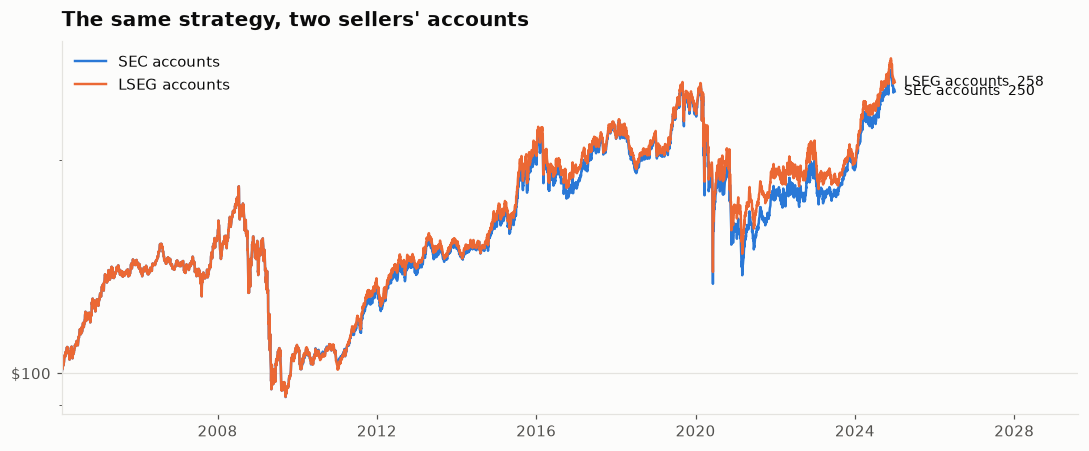

In [5]:
lseg_accounts = run_strategy(cache, replace(config, fundamentals_vendor="refinitiv"), engine=engine)
both = pd.DataFrame({"SEC accounts": result.metrics, "LSEG accounts": lseg_accounts.metrics}).T
display(both[["cagr", "vol", "sharpe", "max_drawdown", "turnover"]])
fig = charts.growth(
    {"SEC accounts": result.backtest.net, "LSEG accounts": lseg_accounts.backtest.net},
    "The same strategy, two sellers' accounts",
)

## Multiple testing and the deflated Sharpe ratio

Test enough strategy variants and one will look excellent by chance alone: the maximum of many noisy Sharpe ratios is
biased upwards, even when every true Sharpe ratio is zero (the *backtest overfitting* problem). So every backtest run
through `run_strategy` is recorded in `research.run`, grouped by *family* (one research hypothesis).

The **deflated Sharpe ratio** (Bailey and López de Prado, 2014) is the probability that the true Sharpe ratio is
positive, after adjusting the benchmark Sharpe for the number of trials in the family and for the non-normality
(skewness and kurtosis) of the returns. Above 0.95 is evidence of skill at the usual 5 % level; 0.5 is no evidence
either way.

The same observed Sharpe ratio becomes less convincing as the number of trials grows:

In [6]:
r = result.backtest.net.dropna()
sharpe, n = float(result.metrics["sharpe"]), len(r)
display(
    pd.Series(
        {trials: deflated_sharpe(sharpe=sharpe, trials=trials, observations=n) for trials in (1, 5, 10, 30, 100)},
        name=f"chance it is real (Sharpe {sharpe:.2f})",
    )
    .rename_axis("versions tried")
    .to_frame()
    .style.format("{:.1%}")
)

,chance it is real (Sharpe 0.35)
versions tried,
1,94.5%
5,65.8%
10,51.0%
30,31.8%
100,17.6%


## The hold-out period

The years from 2025 on are an **out-of-sample hold-out**: no backtest may use them during development, so they cannot
influence design choices. Only a final, chosen strategy is evaluated on them, once. Reusing a hold-out repeatedly
turns it into in-sample data. A request for it now is refused:

In [7]:
try:
    run_strategy(cache, replace(config, end=TODAY), engine=engine)
except HoldoutClosedError as refused:
    print("Refused:", refused)

Refused: the backtest ends 2026-11-20, inside the hold-out from 2025-01-01: end it before, or open the hold-out explicitly (only for a final strategy)


## The book rebuilt on the risk model (specified 20 November 2026, before it ran)

A review of this notebook found that the book above is not market-neutral. Each leg is scaled so its beta is 1, so a
low-beta long leg is levered up and a high-beta short leg scaled down: on 8 June 2020 the book was **179 % long and
94 % short**, a net-long, levered book whose size rests on beta estimates. Its 2020 trough is that week: distressed
energy shares in the short leg (Valaris, Noble, Oasis, Denbury) more than doubled on 5 and 8 June, the "junk rally",
and the book lost 24 % in two days. Its daily beta to SPY is 0.19, not 0. And averaging the four scores did not
diversify: quality alone beat the mix on Sharpe ratio and drawdown.

The rebuilt book changes the construction and the signals, as notebook 3.7 does for the long-only book:

| Setting | The book above | Rebuilt |
|---|---|---|
| Signals | value, quality, momentum, low volatility | quality, net issuance, earnings value, 4-month consensus revisions (each z-scored again, a missing one neutral), ranked within sectors |
| Legs | top and bottom tenth, equally weighted, each scaled to a beta of 1 | tilts by score over specific risk on notebook 4.2's risk model: **dollar-neutral, beta-neutral, sector- and size-neutral**, at most 1 % in a name either way |
| Size | whatever the beta scaling gives (1.4 long and 0.7 short on average; 1.8 and 0.9 on 8 June 2020) | **100 % long and 100 % short** (gross capped at 2: a book this diversified and this neutral has a predicted volatility of only ~3.6 % at that size) |

Family `revised_ls`, one run, January 2004 - December 2024, the universe's costs and borrowing fees. **The pass mark,
written before the run:** a Sharpe ratio after costs and borrowing above the book above's, and a beta to SPY between
-0.1 and +0.1. Sharpe ratios and betas do not depend on the book's size, so the two books compare though the rebuilt
one is far less volatile.

left out 1078 facts of 2 companies in ['GBP']


left out 1078 facts of 2 companies in ['GBP']


Registered as research run 219


,cagr,vol,sharpe,max_drawdown,turnover,beta to SPY,long (average),short (average)
four-factor book (above),4.5%,16.4%,0.35,-50%,7.0,+0.19,1.40,-0.74
rebuilt book,1.0%,3.8%,0.27,-23%,8.4,-0.00,1.00,-1.00


,four-factor book (above),rebuilt book
trade_date,,
2004,+25.4%,+3.7%
2005,+13.1%,+5.6%
2006,+0.8%,-3.3%
2007,+8.4%,+6.8%
2008,-1.1%,+7.3%
2009,-29.6%,+0.6%
2010,-3.6%,-3.3%
2011,+26.8%,+5.2%
2012,+4.6%,-1.7%


,met
Sharpe ratio above the four-factor book's,False
beta to SPY between -0.1 and +0.1,True


The rebuilt book does NOT pass its pass mark


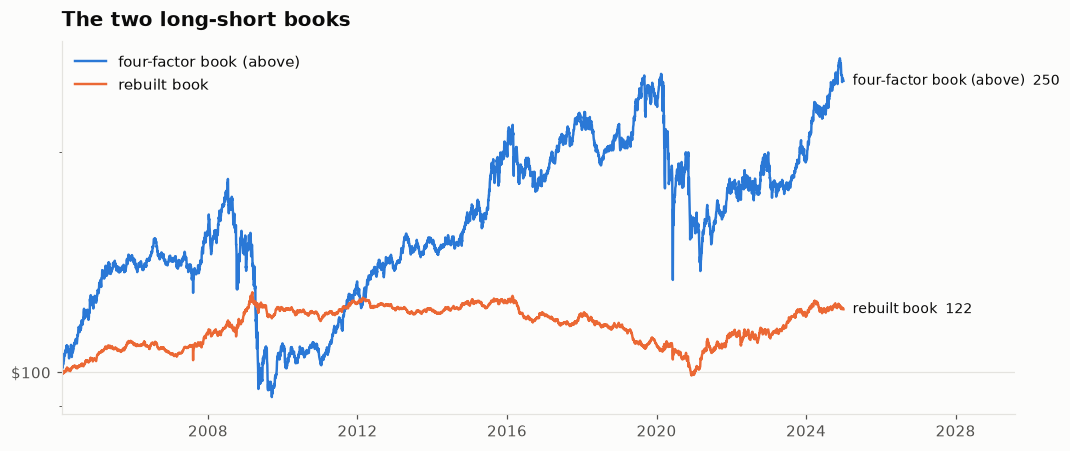

In [8]:
REVISED = (("quality", 1.0), ("issuance", 1.0), ("earnings_value", 1.0), ("consensus_revisions", 1.0))
rebuilt_config = replace(
    config,
    family="revised_ls",
    factors=REVISED,
    mix="standardised",
    within_sectors=True,
    construction="tilted",
    risk=0.10,  # an upper bound: the gross cap binds first
    max_active=0.01,
    neutral=("sector", "size"),
    gross=2.0,
)
rebuilt = run_strategy(cache, rebuilt_config, engine=engine)
print("Registered as research run", rebuilt.run_id)
books = {"four-factor book (above)": result, "rebuilt book": rebuilt}
compare = pd.DataFrame({name: r.metrics for name, r in books.items()}).T[
    ["cagr", "vol", "sharpe", "max_drawdown", "turnover"]
]
compare["beta to SPY"] = [tracking(r.backtest.net, spy)["beta"] for r in books.values()]
compare["long (average)"] = [r.book.clip(lower=0).sum(axis=1).mean() for r in books.values()]
compare["short (average)"] = [r.book.clip(upper=0).sum(axis=1).mean() for r in books.values()]
display(
    compare.style.format(
        {
            "cagr": "{:.1%}",
            "vol": "{:.1%}",
            "sharpe": "{:.2f}",
            "max_drawdown": "{:.0%}",
            "turnover": "{:.1f}",
            "beta to SPY": "{:+.2f}",
            "long (average)": "{:.2f}",
            "short (average)": "{:.2f}",
        }
    )
)
fig = charts.growth({name: r.backtest.net for name, r in books.items()}, "The two long-short books")
yearly = calendar_years({name: r.backtest.net for name, r in books.items()})
display(yearly.style.format("{:+.1%}"))
conditions = {
    "Sharpe ratio above the four-factor book's": bool(compare.iloc[1]["sharpe"] > compare.iloc[0]["sharpe"]),
    "beta to SPY between -0.1 and +0.1": bool(abs(compare.iloc[1]["beta to SPY"]) <= 0.1),
}
display(pd.Series(conditions, name="met").to_frame())
print("The rebuilt book", "PASSES" if all(conditions.values()) else "does NOT pass", "its pass mark")

### What the rebuilt book showed (run 219, 20 November 2026)

**It does not pass.** It is market-neutral as built - a beta to SPY of -0.00 against the old book's +0.19 - but its
Sharpe ratio after costs and borrowing is 0.27, below the four-factor book's 0.35. It returned 1.0 % a year at a
volatility of 3.8 % (the old book: 4.5 % at 16.4 %).

* **What neutrality bought.** The old book's worst years were market and junk-rally years: 2009 (-29.6 %) and 2020
  (-31.3 %). The rebuilt book made +7.3 % in 2008 and +0.6 % in 2009; its maximum drawdown is -23 % against -50 %.
* **What it showed about the signals.** A book with no beta, sector or size bet earns only what its signals earn, and
  from 2016 to 2020 they lost five years running (-3.5, -0.2, -2.7, -6.2 and -9.2 %). The volatility was as the risk
  model predicted (3.8 % against ~3.6 %), but the losses came in a run that a volatility does not show: the -23 %
  drawdown is six times a year's volatility.
* **Part of the old book's Sharpe ratio was the market's:** it was on average 1.40 long and 0.74 short, with a beta of
  0.19 to SPY in a market that rose about 10 % a year.
* **Turnover is 8.4 a year** at 100 % long and 100 % short, against the old book's 7.0.

The pass mark was written before the run and stands: the rebuilt book is not adopted.

## Glossary

* **Factor** - a measurable stock characteristic associated with differences in expected returns.
* **z-score** - a value's distance from the cross-sectional mean in standard deviations; 0 is average.
* **Rebalance** - the date the portfolio is traded back to its target holdings (here: every month end).
* **Turnover** - the fraction of the portfolio traded per year; 3.0 means the whole book is replaced three times.
* **Sharpe ratio** - annualised excess return divided by annualised volatility: return per unit of total risk. For an
  equity strategy, above 0.5 is respectable and above 1 is strong.
* **Beta** - the sensitivity of a portfolio's return to the market's, from a regression of one on the other.
* **Maximum drawdown** - the largest peak-to-trough decline (the deepest point of the drawdown chart).
* **Hold-out** - the most recent years, reserved for a single out-of-sample test.

**Next:** notebook 3.1 builds a long-only version that an investor who cannot short could hold.